In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
# load the dataset
df = pd.read_csv(r"C:\Users\AKSHAT KUMAR\Retail Banking Analytics\data\P6-UK-Bank-Customers.csv")
df.shape

(4014, 9)

In [8]:
# dataset head
df.head()

,Customer ID,Name,Surname,Gender,Age,Region,Job Classification,Date Joined,Balance
0,100000001,Simon,Walsh,Male,21,England,White Collar,05.Jan.15,113810.15
1,400000002,Jasmine,Miller,Female,34,Northern Ireland,Blue Collar,06.Jan.15,36919.73
2,100000003,Liam,Brown,Male,46,England,White Collar,07.Jan.15,101536.83
3,300000004,Trevor,Parr,Male,32,Wales,White Collar,08.Jan.15,1421.52
4,100000005,Deirdre,Pullman,Female,38,England,Blue Collar,09.Jan.15,35639.79


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4014 entries, 0 to 4013
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer ID         4014 non-null   int64  
 1   Name                4014 non-null   object 
 2   Surname             4014 non-null   object 
 3   Gender              4014 non-null   object 
 4   Age                 4014 non-null   int64  
 5   Region              4014 non-null   object 
 6   Job Classification  4014 non-null   object 
 7   Date Joined         4014 non-null   object 
 8   Balance             4014 non-null   float64
dtypes: float64(1), int64(2), object(6)
memory usage: 282.4+ KB


In [10]:
# check missing values
df.isnull().sum()

Customer ID           0
Name                  0
Surname               0
Gender                0
Age                   0
Region                0
Job Classification    0
Date Joined           0
Balance               0
dtype: int64

In [17]:
# describe the data
df[['Age', 'Balance']].describe()

,Age,Balance
count,4014.000000,4014.000000
mean,38.611111,39766.448274
std,9.819121,29859.489192
min,15.000000,11.520000
25%,31.000000,16115.367500
50%,37.000000,33567.330000
75%,45.000000,57533.930000
max,64.000000,183467.700000


In [19]:
# inspecting categories
df[['Gender','Region', 'Job Classification']].value_counts()

Gender  Region            Job Classification
Female  England           White Collar          757
Male    England           White Collar          744
        Scotland          Blue Collar           517
Female  Scotland          Other                 263
Male    Scotland          Other                 233
Female  Wales             White Collar          189
Male    England           Blue Collar           181
Female  England           Other                 171
                          Blue Collar           163
Male    England           Other                 143
        Wales             White Collar          116
Female  Northern Ireland  Other                  93
Male    Wales             Blue Collar            84
Female  Wales             Other                  57
Male    Scotland          White Collar           55
        Wales             Other                  38
Female  Wales             Blue Collar            36
        Northern Ireland  White Collar           35
Male    Northern Ir

In [20]:
# checking duplicates
df.duplicated().sum()

0

In [21]:
# check date values
df['Date Joined'].head(10)

0    05.Jan.15
1    06.Jan.15
2    07.Jan.15
3    08.Jan.15
4    09.Jan.15
5    09.Jan.15
6    11.Jan.15
7    11.Jan.15
8    11.Jan.15
9    12.Jan.15
Name: Date Joined, dtype: object

In [22]:
# converting joining dates to datetime
df['Date Joined'] = pd.to_datetime(
    df['Date Joined'],
    format="%d.%b.%y",
    errors="coerce"
)

In [24]:
# verifying Date Joined column
df['Date Joined'].isna().sum()

0

In [26]:
# getting range of dates
df['Date Joined'].min(), df['Date Joined'].max()

(Timestamp('2015-01-05 00:00:00'), Timestamp('2015-12-30 00:00:00'))

In [27]:
# Core banking customer KPIs
total_customers = df["Customer ID"].nunique()
average_age = df["Age"].mean()
average_balance = df["Balance"].mean()
total_balance = df["Balance"].sum()

print(f"Total Customers: {total_customers:,}")
print(f"Average Age: {average_age:.2f}")
print(f"Average Balance: {average_balance:,.2f}")
print(f"Total Recorded Balance: {total_balance:,.2f}")

Total Customers: 4,014
Average Age: 38.61
Average Balance: 39,766.45
Total Recorded Balance: 159,622,523.37


In [32]:
# customer segements
print("Customers by Region")
df["Region"].value_counts()


Customers by Region


Region
England             2159
Scotland            1124
Wales                520
Northern Ireland     211
Name: count, dtype: int64

In [30]:
print("Customers by Gender")
df["Gender"].value_counts()

Customers by Gender


Gender
Male      2165
Female    1849
Name: count, dtype: int64

In [31]:
print("Customers by Job Classification")
df["Job Classification"].value_counts()

Customers by Job Classification


Job Classification
White Collar    1955
Blue Collar     1049
Other           1010
Name: count, dtype: int64

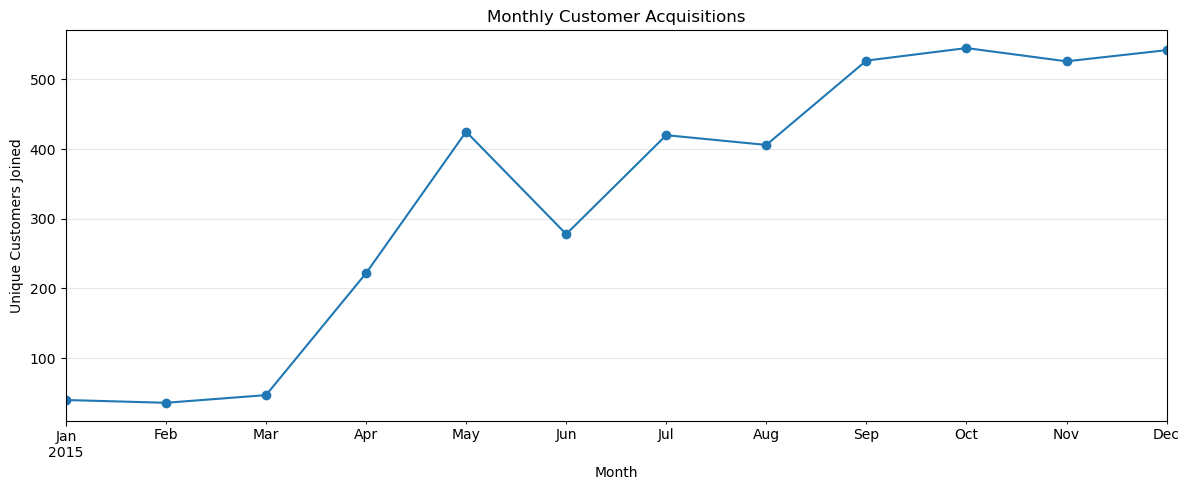

In [33]:
# Number of customers joining each month
monthly_customers = (
    df.set_index("Date Joined")
      .resample("ME")["Customer ID"]
      .nunique()
)

monthly_customers.plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly Customer Acquisitions"
)

plt.xlabel("Month")
plt.ylabel("Unique Customers Joined")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
region_analysis = (
    df.groupby("Region")
      .agg(
          Total_Customers=("Customer ID", "nunique"),
          Average_Balance=("Balance", "mean"),
          Total_Balance=("Balance", "sum"),
          Average_Age=("Age", "mean")
      )
      .sort_values("Total_Balance", ascending=False)
      .round(2)
)

display(region_analysis)

,Total_Customers,Average_Balance,Total_Balance,Average_Age
Region,,,,
England,2159,39292.91,84833397.00,34.79
Scotland,1124,39511.33,44410730.72,49.20
Wales,520,42390.06,22042829.26,34.99
Northern Ireland,211,39505.05,8335566.39,30.28


In [35]:
job_analysis = (
    df.groupby("Job Classification")
      .agg(
          Total_Customers=("Customer ID", "nunique"),
          Average_Balance=("Balance", "mean"),
          Total_Balance=("Balance", "sum"),
          Median_Balance=("Balance", "median")
      )
      .sort_values("Average_Balance", ascending=False)
      .round(2)
)

display(job_analysis)

,Total_Customers,Average_Balance,Total_Balance,Median_Balance
Job Classification,,,,
White Collar,1955,39931.40,78065883.04,32658.92
Other,1010,39824.34,40222584.83,35266.30
Blue Collar,1049,39403.29,41334055.50,33570.99


In [36]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56+"
    ],
    right=True
)

age_analysis = (
    df.groupby("Age Group", observed=True)
      .agg(
          Total_Customers=("Customer ID", "nunique"),
          Average_Balance=("Balance", "mean"),
          Total_Balance=("Balance", "sum")
      )
      .round(2)
)

display(age_analysis)

,Total_Customers,Average_Balance,Total_Balance
Age Group,,,
18-25,303,38506.68,11667523.86
26-35,1379,40004.44,55166128.21
36-45,1367,39554.39,54070855.80
46-55,714,39692.46,28340418.36
56+,251,41345.01,10377597.14


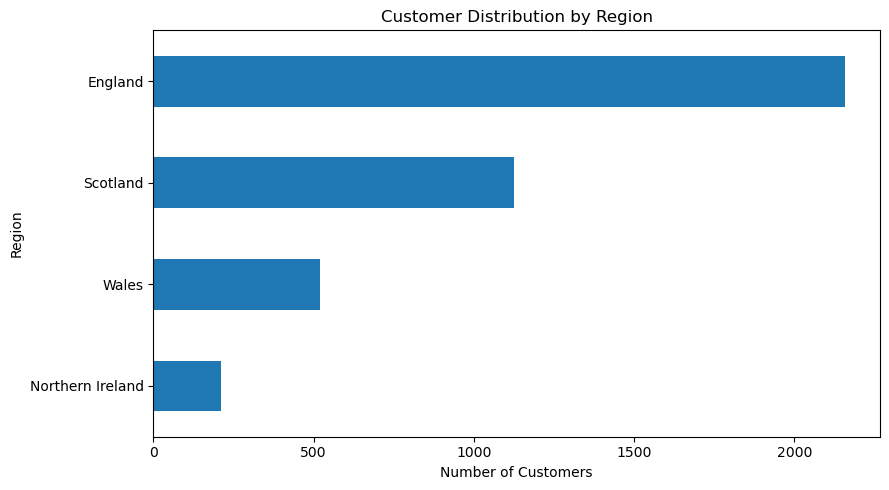

In [37]:
region_analysis["Total_Customers"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Customer Distribution by Region",
    xlabel="Number of Customers",
    ylabel="Region"
)

plt.tight_layout()
plt.show()

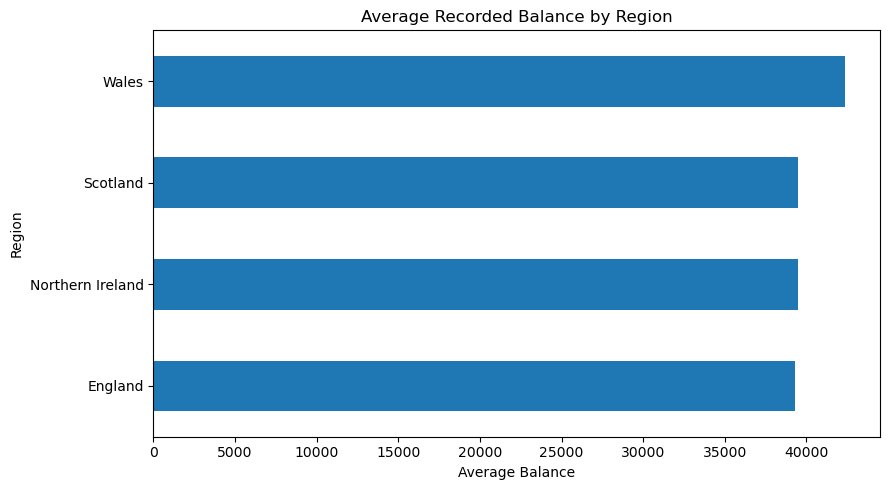

In [38]:
region_analysis["Average_Balance"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Average Recorded Balance by Region",
    xlabel="Average Balance",
    ylabel="Region"
)

plt.tight_layout()
plt.show()

In [39]:
# Create a year-month field for time-based analysis
df["Join Year-Month"] = df["Date Joined"].dt.to_period("M").astype(str)

# Create a reusable age group column
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["25 and under", "26-35", "36-45", "46-55", "56+"]
)

# Clean column names
df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(" ", "_")
)

display(df.head())

,customer_id,name,surname,gender,age,region,job_classification,date_joined,balance,age_group,join_year-month
0,100000001,Simon,Walsh,Male,21,England,White Collar,2015-01-05,113810.15,25 and under,2015-01
1,400000002,Jasmine,Miller,Female,34,Northern Ireland,Blue Collar,2015-01-06,36919.73,26-35,2015-01
2,100000003,Liam,Brown,Male,46,England,White Collar,2015-01-07,101536.83,46-55,2015-01
3,300000004,Trevor,Parr,Male,32,Wales,White Collar,2015-01-08,1421.52,26-35,2015-01
4,100000005,Deirdre,Pullman,Female,38,England,Blue Collar,2015-01-09,35639.79,36-45,2015-01


In [40]:
df.to_csv(
    "../data/retail_banking_analytics_clean.csv",
    index=False
)